In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram

# Step 1: Student data

students = ['A', 'B', 'C', 'D', 'E', 'F']
marks = [30, 35, 40, 80, 85, 90]

x = np.arange(len(students))
marks_array = np.array(marks)


# Step 2: Clustering phases

phases = [
    [[0], [1], [2], [3], [4], [5]],
    [[0, 1], [2], [3], [4], [5]],
    [[0, 1, 2], [3], [4], [5]],
    [[0, 1, 2], [3, 4], [5]],
    [[0, 1, 2], [3, 4, 5]],
    [[0, 1, 2, 3, 4, 5]]
]

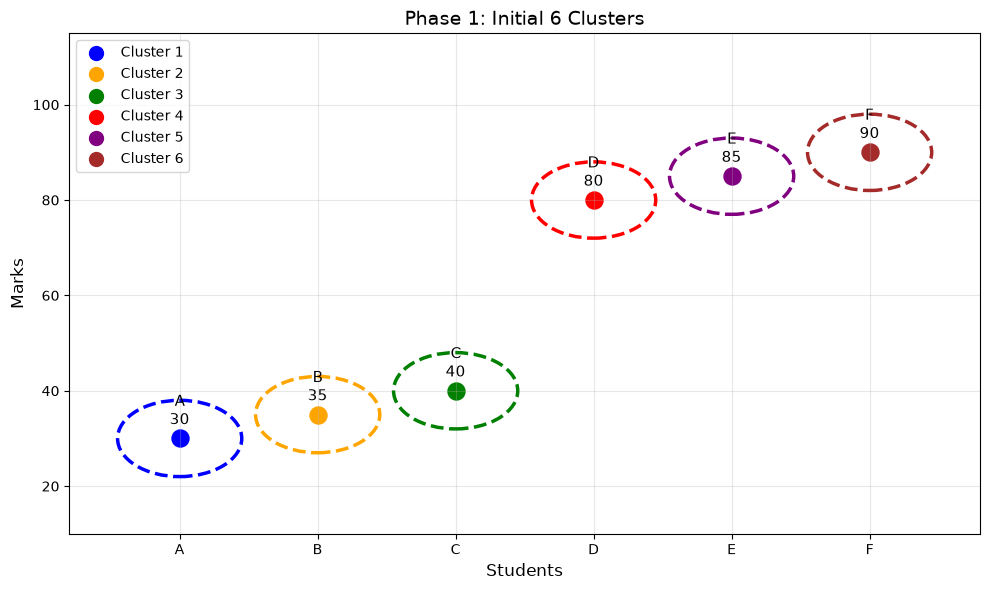

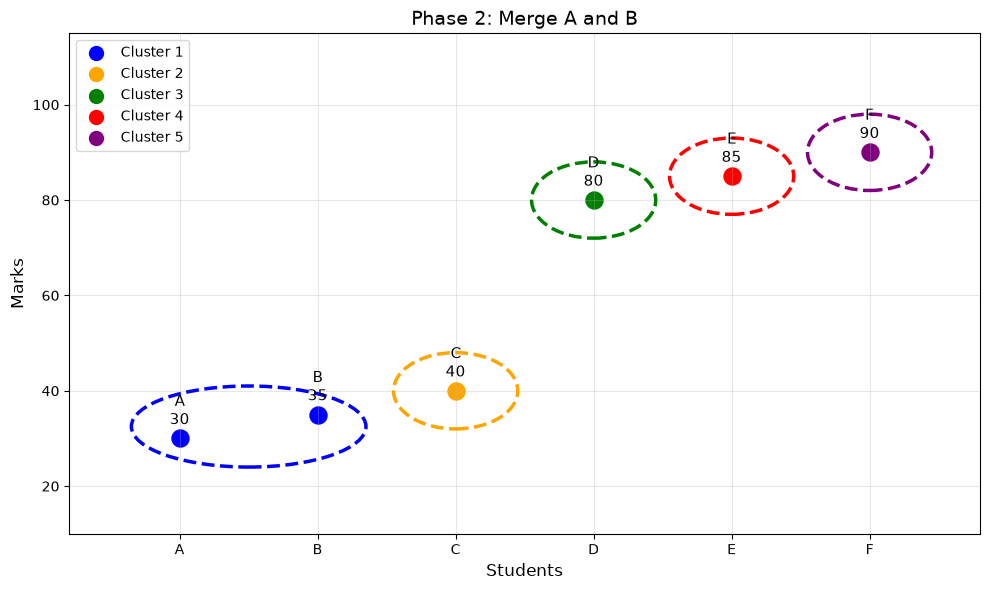

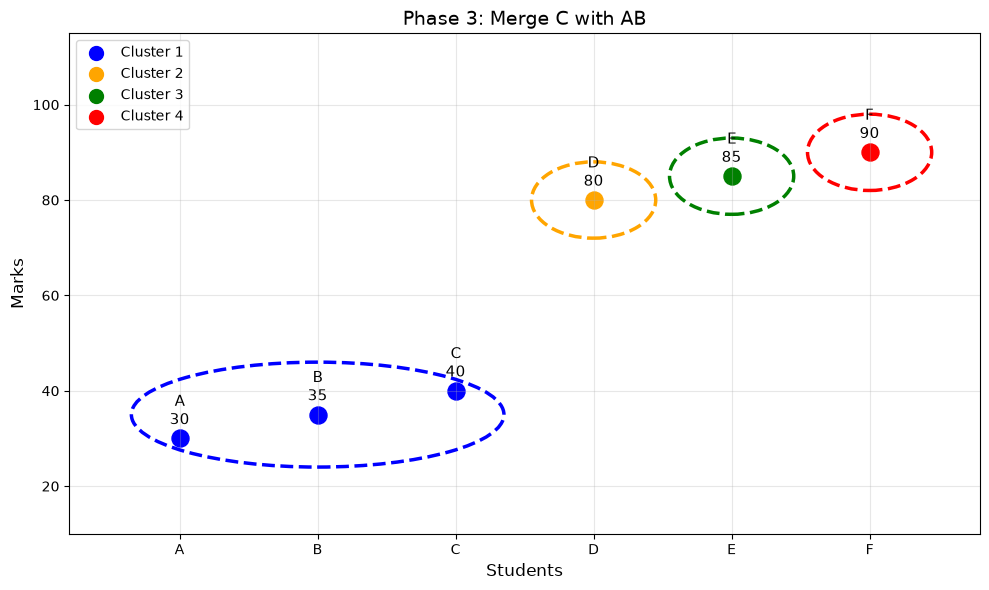

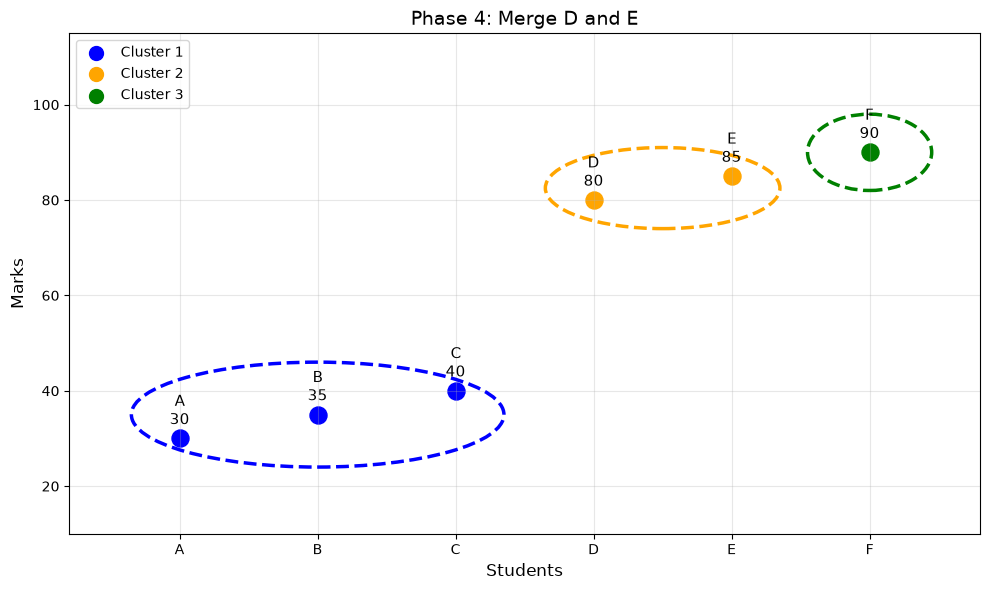

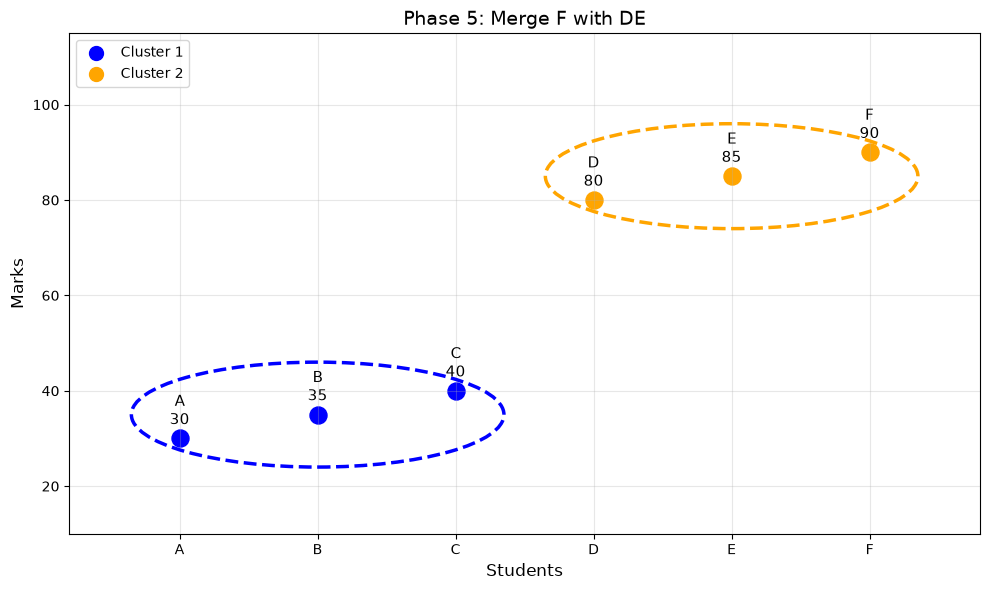

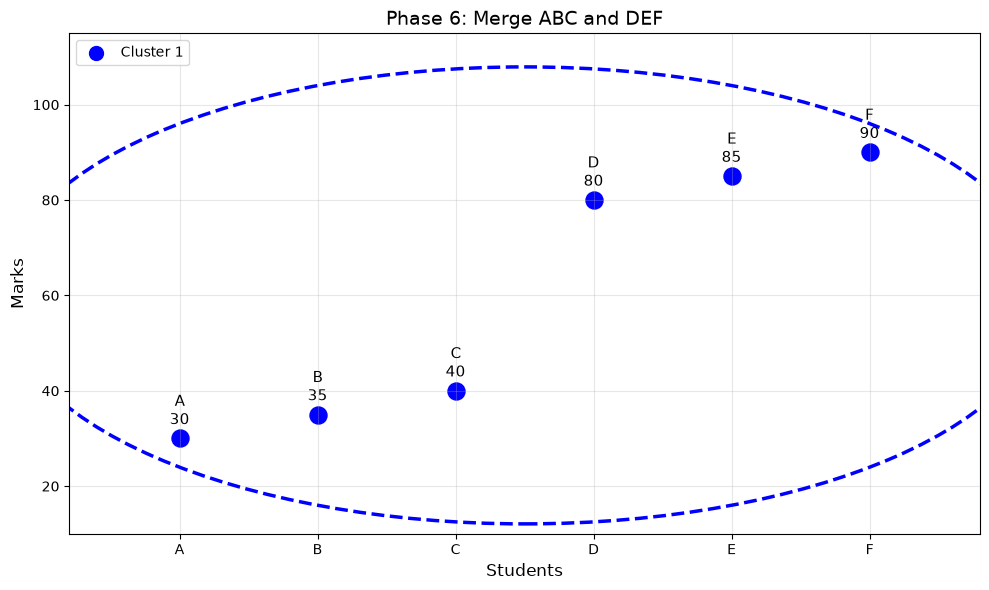

In [9]:
titles = [
    "Phase 1: Initial 6 Clusters",
    "Phase 2: Merge A and B",
    "Phase 3: Merge C with AB",
    "Phase 4: Merge D and E",
    "Phase 5: Merge F with DE",
    "Phase 6: Merge ABC and DEF"
]

colors = [
    'blue', 'orange', 'green',
    'red', 'purple', 'brown'
]


# Step 3: Draw each clustering phase

for phase_no, clusters in enumerate(phases):

    fig, ax = plt.subplots(figsize=(10, 6))

    for cluster_no, cluster in enumerate(clusters):

        color = colors[cluster_no]

        cluster_x = x[cluster]
        cluster_y = marks_array[cluster]

        # Plot students
        ax.scatter(
            cluster_x,
            cluster_y,
            color=color,
            s=150
        )

        # Display student names and marks
        for i in cluster:

            ax.text(
                x[i],
                marks[i] + 3,
                f"{students[i]}\n{marks[i]}",
                ha='center',
                fontsize=11
            )

        # Calculate ellipse to cover ALL points

        center_x = np.mean(cluster_x)
        center_y = np.mean(cluster_y)

        # Initial horizontal and vertical radii
        radius_x = max(
            np.max(np.abs(cluster_x - center_x)) + 0.35,
            0.45
        )

        radius_y = max(
            np.max(np.abs(cluster_y - center_y)) + 6,
            8
        )

        # Check the distance of every point from the centre
        distances = np.sqrt(
            ((cluster_x - center_x) / radius_x) ** 2 +
            ((cluster_y - center_y) / radius_y) ** 2
        )

        # Increase ellipse size if any point is outside
        scale = max(1.0, np.max(distances) * 1.10)

        radius_x *= scale
        radius_y *= scale

        # Draw ellipse
        ellipse = Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            edgecolor=color,
            facecolor='none',
            linewidth=2.5,
            linestyle='--',
            zorder=2
        )

        ax.add_patch(ellipse)

        # Legend
        ax.scatter(
            [],
            [],
            color=color,
            s=100,
            label=f"Cluster {cluster_no + 1}"
        )

    # Graph formatting
    ax.set_title(titles[phase_no], fontsize=14)

    ax.set_xlabel("Students", fontsize=12)
    ax.set_ylabel("Marks", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(students)

    ax.set_xlim(-0.8, 5.8)
    ax.set_ylim(10, 115)

    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

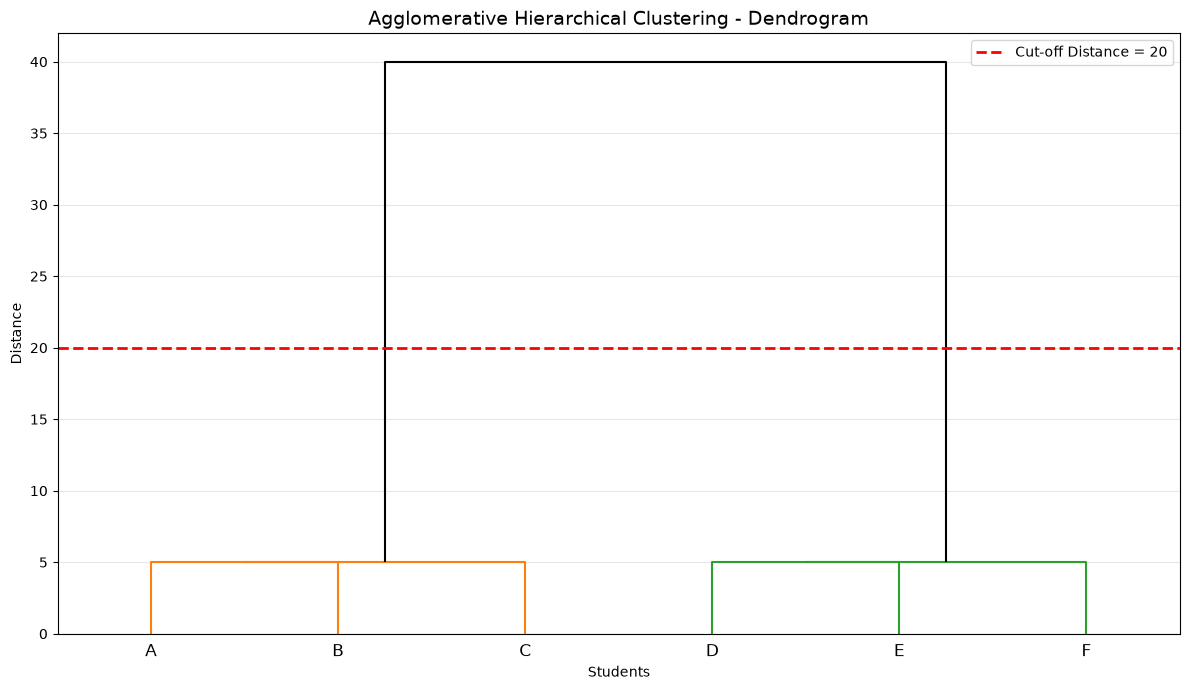

In [10]:
#
# Step 4: Create linkage matrix
#

Z = np.array([
    [0, 1, 5, 2],
    [6, 2, 5, 3],
    [3, 4, 5, 2],
    [8, 5, 5, 3],
    [7, 9, 40, 6]
], dtype=np.float64)


# A + B
# AB + C
# D + E
# DE + F
# ABC + DEF


# Step 5: Draw dendrogram
#

plt.figure(figsize=(12, 7))

dendrogram(
    Z,
    labels=students,
    color_threshold=20,
    above_threshold_color='black'
)

plt.axhline(
    y=20,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Cut-off Distance = 20'
)

plt.title(
    "Agglomerative Hierarchical Clustering - Dendrogram",
    fontsize=14
)

plt.xlabel("Students")
plt.ylabel("Distance")

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()